# S&OP forecast and safety stock

Monthly US retail sales by category, from the Census Monthly Retail Trade Survey.

Questions I wanted to answer:
1. Which simple forecast method holds up best on the last 12 months?
2. How much safety stock does each method need for the same service level?
3. What does each extra point of service cost in inventory?

The output CSVs in `../tableau/` feed the Tableau dashboard.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.holtwinters import ExponentialSmoothing

pd.set_option("display.float_format", "{:,.3f}".format)
HOLDOUT = 12   # months held back for testing
SEASON = 12

## 1. Load the data

`../data.csv` is the same file the interactive model uses. It was pulled from FRED.
To refresh it, read each series straight from FRED, for example
`pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=MRTSSM4413USN")`.

In [2]:
raw = pd.read_csv("../data.csv")
sales = (raw[raw.metric == "sales_nsa"]
         .assign(month=lambda d: pd.to_datetime(d.month))
         .pivot(index="month", columns="category", values="value")
         .asfreq("MS"))
ratio = (raw[raw.metric == "inv_sales_ratio_sa"]
         .assign(month=lambda d: pd.to_datetime(d.month)))
print(sales.shape, sales.index.min().date(), "to", sales.index.max().date())
sales.tail(3)

(140, 8) 2015-01-01 to 2026-08-01


category,"Auto parts, accessory and tire stores",Building materials and garden stores,Clothing and accessories stores,Furniture and home furnishings stores,General merchandise stores,Grocery stores,Health and personal care stores,"Sporting goods, hobby, music and book stores"
month,,,,,,,,
2026-06-01,"12,262.000","49,977.000","24,586.000","10,518.000","79,132.000","75,534.000","38,528.000","8,611.000"
2026-07-01,"12,325.000","47,548.000","26,161.000","10,770.000","81,243.000","78,734.000","38,544.000","8,623.000"
2026-08-01,"12,437.000","44,570.000","27,302.000","10,760.000","83,627.000","77,628.000","38,620.000","9,495.000"


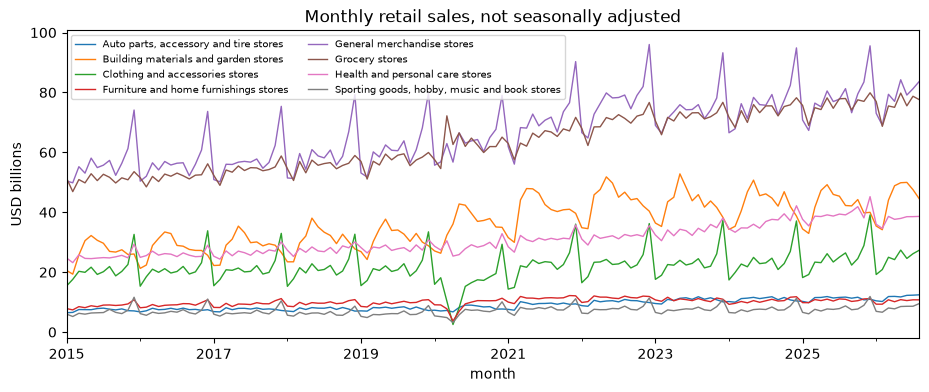

In [3]:
ax = (sales / 1000).plot(figsize=(11, 4), lw=1)
ax.set_ylabel("USD billions"); ax.set_title("Monthly retail sales, not seasonally adjusted")
ax.legend(fontsize=7, ncol=2); plt.show()

## 2. Backtest three methods

Train on everything before the last 12 months. Forecast those 12 months in one go, the way a frozen plan works.

- **Naive**: last known month, repeated.
- **Seasonal naive**: same month last year.
- **ETS**: Holt-Winters with a damped additive trend and multiplicative seasonality (statsmodels).

In [4]:
def backtest(y, h=HOLDOUT):
    train, test = y.iloc[:-h], y.iloc[-h:]
    fc = pd.DataFrame(index=test.index)
    fc["Naive"] = train.iloc[-1]
    fc["Seasonal naive"] = train.iloc[-SEASON:].values[:h] if h <= SEASON else np.tile(train.iloc[-SEASON:].values, 2)[:h]
    ets = ExponentialSmoothing(train, trend="add", damped_trend=True,
                               seasonal="mul", seasonal_periods=SEASON).fit(optimized=True)
    fc["ETS"] = ets.forecast(h).values
    return test, fc

def scores(actual, fc):
    e = fc.sub(actual, axis=0)
    return pd.DataFrame({
        "MAPE": (e.abs().div(actual, axis=0)).mean(),
        "WAPE": e.abs().sum() / actual.sum(),
        "Bias": e.sum() / actual.sum(),
        "RMSE": np.sqrt((e ** 2).mean()),
    })

rows, fcs = [], {}
for cat in sales.columns:
    test, fc = backtest(sales[cat].dropna())
    s = scores(test, fc).reset_index(names="method")
    s.insert(0, "category", cat)
    s["best"] = s.WAPE == s.WAPE.min()
    rows.append(s); fcs[cat] = (test, fc)
acc = pd.concat(rows, ignore_index=True)
acc.pivot(index="category", columns="method", values="WAPE").style.format("{:.1%}").highlight_min(axis=1, color="#3a3220")

method,ETS,Naive,Seasonal naive
category,,,
"Auto parts, accessory and tire stores",3.1%,5.2%,3.6%
Building materials and garden stores,3.6%,10.2%,4.1%
Clothing and accessories stores,2.4%,13.4%,5.4%
Furniture and home furnishings stores,2.5%,5.3%,2.9%
General merchandise stores,1.6%,6.3%,2.6%
Grocery stores,1.7%,3.1%,1.5%
Health and personal care stores,6.1%,5.0%,3.3%
"Sporting goods, hobby, music and book stores",5.6%,12.4%,6.7%


In [5]:
wins = acc[acc.best].method.value_counts()
print("Categories won by each method:"); print(wins.to_string())

Categories won by each method:
method
ETS               6
Seasonal naive    2


ETS wins 6 of the 8 categories. Seasonal naive wins grocery and health and personal care. Naive never wins, because every category is strongly seasonal.
Health and personal care is the odd one: ETS does worse there than even naive. Worth checking for a level shift in the holdout year before trusting a smoothed trend.

## 3. Forward plan

Refit ETS on the full history and forecast the next 12 months. The 80 percent band uses the holdout RMSE.

In [6]:
fwd_rows = []
for cat in sales.columns:
    y = sales[cat].dropna()
    model = ExponentialSmoothing(y, trend="add", damped_trend=True,
                                 seasonal="mul", seasonal_periods=SEASON).fit(optimized=True)
    f = model.forecast(12)
    rmse = acc[(acc.category == cat) & (acc.method == "ETS")].RMSE.iloc[0]
    for m, v in f.items():
        fwd_rows.append({"category": cat, "month": m, "forecast": v,
                         "lower80": v - 1.2816 * rmse, "upper80": v + 1.2816 * rmse})
fwd = pd.DataFrame(fwd_rows)
fwd.head()

,category,month,forecast,lower80,upper80
0,"Auto parts, accessory and tire stores",2026-09-01,"11,718.471","11,168.209","12,268.732"
1,"Auto parts, accessory and tire stores",2026-10-01,"12,168.222","11,617.961","12,718.484"
2,"Auto parts, accessory and tire stores",2026-11-01,"11,401.031","10,850.769","11,951.292"
3,"Auto parts, accessory and tire stores",2026-12-01,"11,135.284","10,585.022","11,685.545"
4,"Auto parts, accessory and tire stores",2027-01-01,"10,801.640","10,251.378","11,351.901"


## 4. Safety stock and the service ladder

Planning assumptions (not data): supplier lead time 6 weeks, lead time std dev 1 week, review every 2 weeks,
supplier on-time 96 percent, carrying cost 25 percent a year.

Safety stock = z × √(L × σ² + D² × σL²), with σ = forecast RMSE of the method, D = average forecast demand.
Fill rate uses the normal loss function. OTIF = fill rate × on-time rate.

In [7]:
LT_W, LT_SD_W, REVIEW_W, ONTIME, CARRY = 6, 1, 2, 0.96, 0.25
L = (LT_W + REVIEW_W) / 4.345
SL_ = LT_SD_W / 4.345
levels = [0.80, 0.85, 0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995, 0.999]

def loss(z):
    return norm.pdf(z) - z * (1 - norm.cdf(z))

ladder = []
for cat in sales.columns:
    D = fwd[fwd.category == cat].forecast.mean()
    Q = D * REVIEW_W / 4.345
    for method in ["Naive", "Seasonal naive", "ETS"]:
        sigma = acc[(acc.category == cat) & (acc.method == method)].RMSE.iloc[0]
        sig_l = np.sqrt(L * sigma ** 2 + D ** 2 * SL_ ** 2)
        for sl in levels:
            z = norm.ppf(sl)
            ss = z * sig_l
            fill = max(0.0, 1 - sig_l * loss(z) / Q)
            inv = Q / 2 + ss
            ladder.append({"category": cat, "method": method, "service_level": sl, "z": z,
                           "safety_stock": ss, "months_of_supply": inv / D, "fill_rate": fill,
                           "otif": fill * ONTIME, "carrying_cost": inv * CARRY})
ladder = pd.DataFrame(ladder)
ladder[(ladder.category == ladder.category.iloc[0]) & (ladder.method == "ETS")]

,category,method,service_level,z,safety_stock,months_of_supply,fill_rate,otif,carrying_cost
24,"Auto parts, accessory and tire stores",ETS,0.800,0.842,"2,352.241",0.428,0.943,0.905,"1,271.434"
25,"Auto parts, accessory and tire stores",ETS,0.850,1.036,"2,896.720",0.474,0.960,0.922,"1,407.554"
26,"Auto parts, accessory and tire stores",ETS,0.900,1.282,"3,581.799",0.532,0.976,0.937,"1,578.824"
27,"Auto parts, accessory and tire stores",ETS,0.920,1.405,"3,927.024",0.561,0.981,0.942,"1,665.130"
28,"Auto parts, accessory and tire stores",ETS,0.940,1.555,"4,345.425",0.596,0.987,0.947,"1,769.730"
29,"Auto parts, accessory and tire stores",ETS,0.950,1.645,"4,597.189",0.617,0.989,0.950,"1,832.671"
30,"Auto parts, accessory and tire stores",ETS,0.960,1.751,"4,892.979",0.642,0.992,0.952,"1,906.619"
31,"Auto parts, accessory and tire stores",ETS,0.970,1.881,"5,256.616",0.673,0.994,0.954,"1,997.528"
32,"Auto parts, accessory and tire stores",ETS,0.980,2.054,"5,740.007",0.713,0.996,0.956,"2,118.376"
33,"Auto parts, accessory and tire stores",ETS,0.990,2.326,"6,501.892",0.778,0.998,0.958,"2,308.847"


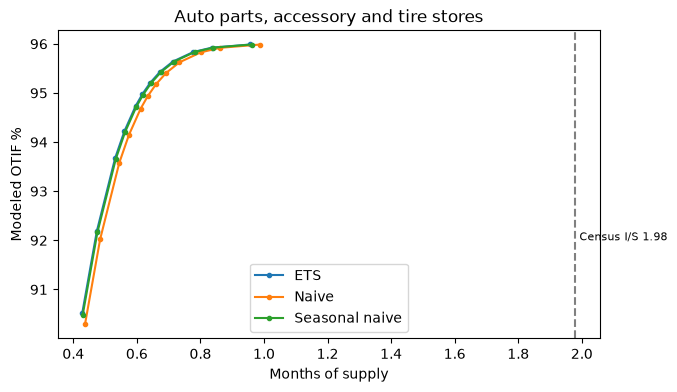

In [8]:
cat = "Auto parts, accessory and tire stores"
sub = ladder[(ladder.category == cat)]
fig, ax = plt.subplots(figsize=(7, 4))
for m, g in sub.groupby("method"):
    ax.plot(g.months_of_supply, g.otif * 100, marker="o", ms=3, label=m)
r = ratio[ratio.category == cat].sort_values("month").value.iloc[-1]
ax.axvline(r, ls="--", c="gray"); ax.text(r, 92, f" Census I/S {r:.2f}", fontsize=8)
ax.set_xlabel("Months of supply"); ax.set_ylabel("Modeled OTIF %"); ax.legend(); ax.set_title(cat)
plt.show()

The forecast method matters less than lead time variability here. At these settings most of the buffer
comes from the 1 week lead time spread, not from forecast error. A steadier supplier would cut more stock
than a better forecast.

The Census inventory to sales ratio sits well to the right of the curve. Real stores carry slow movers,
display stock and seasonal builds that this model does not include, so this is a gap to explain, not a saving to book.

## 5. Export for Tableau

In [9]:
out = "../tableau/"
# actuals + backtests + forward plan in one long table
long = []
for cat in sales.columns:
    y = sales[cat].dropna()
    for m, v in y.items():
        long.append({"category": cat, "month": m, "series": "Actual", "value": v, "phase": "History"})
    test, fc = fcs[cat]
    for meth in fc.columns:
        for m, v in fc[meth].items():
            long.append({"category": cat, "month": m, "series": meth, "value": v, "phase": "Backtest"})
for _, r_ in fwd.iterrows():
    long.append({"category": r_.category, "month": r_.month, "series": "ETS forward", "value": r_.forecast,
                 "phase": "Forward", "lower80": r_.lower80, "upper80": r_.upper80})
long = pd.DataFrame(long)
long["month"] = pd.to_datetime(long.month).dt.strftime("%Y-%m-%d")
long.to_csv(out + "sop_sales_forecast.csv", index=False)
acc.to_csv(out + "sop_accuracy.csv", index=False)
ladder.to_csv(out + "sop_service_ladder.csv", index=False)
(ratio[["month", "category", "ratio_level", "value"]]
   .rename(columns={"value": "inv_sales_ratio"})
   .assign(month=lambda d: d.month.dt.strftime("%Y-%m-%d"))
   .to_csv(out + "sop_inventory_ratio.csv", index=False))
for f in sorted(os.listdir(out)):
    print(f, len(pd.read_csv(out + f)), "rows")

sop_accuracy.csv 24 rows
sop_inventory_ratio.csv 700 rows
sop_sales_forecast.csv 1504 rows
sop_service_ladder.csv 288 rows
